# 36. A first seismic velocity model between LC-36 and the network

The explosion's seismic waves (notebook 26) carry information about the shallow structure along the
12–21 km paths from LC-36:

* **Rayleigh-wave group-velocity dispersion**, measured here by multiple-filter analysis (Gaussian
  narrow-band filters, envelope against group velocity $d/t$) on the verticals;
* **P first-arrival times** at 19–21 km (AIC picks from notebook 26), read as a head wave along the top of
  the fastest layer.

These are fitted with a flat model of two layers over a half-space: a slow surface layer (surficial
sands), an intermediate layer, and a faster half-space (the deeper limestones). A second fit also uses the
ground resonance excited by the airwave (4.5–5.5 Hz, notebook 28), read as the quarter-wavelength S
resonance of the surface layer, $f_0 = V_{S1}/(4h_1)$. Forward modelling uses
`ksclib.surfacewaves`: Rayleigh dispersion from `disba` (Luu 2021) when it is installed, otherwise
`ksclib`'s thin-layer solver (the two agree to 1–1.5%), and head-wave travel times.

Assumptions: the sediments are water-saturated below a shallow water table, so their Vp is set
(1600 and 1900 m/s) rather than inverted; the half-space has Vp/Vs = 1.9; densities are fixed at 1800,
1950 and 2250 kg/m³; and the paths are treated as one 1D structure. The explosion origin is uncertain by
about ±1 s (notebook 24). This is a first model to test against borehole and refraction data, not a
final one.

Needs notebooks 26 and 28 to have been run (it reads `26_seismic_arrivals/seismic_picks.csv` and
`28_air_ground_coupling/layer_resonance.csv`).

Output (`cfg.OUT_DIR / "36_velocity_model"`): `dispersion_picks.csv`, `dispersion_data.csv`, `ftan.png`,
`model_ensemble.csv`, `best_model_A.csv`, `best_model_B.csv`, `velocity_model.png`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import hilbert
from scipy.optimize import minimize

from ksclib import surfacewaves as sw
import newglenn_config as cfg

warnings.filterwarnings('ignore', message='ObsPy can not map unit')
ORIGIN = cfg.ORIGIN
OUT = cfg.output_dir('36_velocity_model')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
air = cfg.airwave_speeds()
STAS = ['B20', 'B14', 'B29', 'B05']
FIT_STAS = ['B14', 'B29', 'B05']          # B20: noisy, flat dispersion (see below)
raw = cfg.event_stream_raw(starttime=ORIGIN - 300, endtime=ORIGIN + 300)
st = cfg.instrument_correct(raw).select(channel='DHZ')
picks = pd.read_csv(cfg.OUT_DIR / '26_seismic_arrivals' / 'seismic_picks.csv').set_index('station')
lay = pd.read_csv(cfg.OUT_DIR / '28_air_ground_coupling' / 'layer_resonance.csv')
F0 = lay[lay.pair.str[:3].isin(['B14', 'B29', 'B05'])].groupby(lay.pair.str[:3]).f0_hz.first()
F0_OBS, F0_SIG = float(F0.mean()), max(float(F0.std()), 0.5)
print('ground resonance (notebook 28):', F0.to_dict(), f'-> {F0_OBS:.2f} +/- {F0_SIG:.2f} Hz')
display(picks[['distance_m', 'aic_2_12_s', 'aic_1_5_s', 'first_arrival_s', 'wavetrain_peak_s']].round(2))

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/ksclib/src/ksclib/centaur.py:123: UserWarning: B14: no Centaur response before 2026-05-29T01:00:02.370000Z; using 1R.B14_20260614T135243Z.xml (16.5 days later)
  warnings.warn(str(m.message))


ground resonance (notebook 28): {'B05': 4.75, 'B14': 4.5, 'B29': 5.5} -> 4.92 +/- 0.52 Hz


,distance_m,aic_2_12_s,aic_1_5_s,first_arrival_s,wavetrain_peak_s
station,,,,,
B20,11793.38,17.33,17.29,NaN,19.08
B14,19311.80,8.16,9.15,8.65,19.81
B29,21002.68,5.55,6.38,5.96,23.23
B05,21303.72,7.84,6.52,7.18,26.13


## Group-velocity dispersion (multiple-filter analysis)

For each centre frequency $f_c$ (0.5–15 Hz), a Gaussian filter $\exp[-\alpha((f - f_c)/f_c)^2]$ with
$\alpha = 20$, the envelope of the filtered vertical between the origin and 2 s before the airwave, plotted
against $U = d/t$. The ridge (largest envelope for 0.36 ≤ U ≤ 4 km/s) is kept where it exceeds 5 times
the same filter's pre-event envelope level.

In [2]:
F = np.geomspace(0.5, 15, 40)
ALPHA = 20.0
UG = np.linspace(0.35, 4.0, 300)
ftan, rows = {}, []
for sta in STAS:
    tr = st.select(station=sta)[0]
    fs = tr.stats.sampling_rate
    d, ta = air.distance_m[sta], air.travel_time_s[sta]
    s = tr.slice(ORIGIN - 120, ORIGIN + ta - 2)
    x = s.data - s.data.mean()
    t = s.times() - 120
    X = np.fft.rfft(x)
    fr = np.fft.rfftfreq(len(x), 1 / fs)
    img = []
    for fc in F:
        env = np.abs(hilbert(np.fft.irfft(X * np.exp(-ALPHA * ((fr - fc) / fc) ** 2), len(x))))
        noise = np.median(env[(t > -100) & (t < -5)])
        m = t > 0.5
        U, e = d / t[m] / 1000, env[m]
        sel = (U >= 0.36) & (U <= 4.0)
        k = np.argmax(e[sel])
        rows.append(dict(station=sta, f_hz=fc, U_km_s=U[sel][k], snr=e[sel][k] / noise))
        img.append(np.interp(UG, U[::-1], e[::-1]) / e[sel].max())
    ftan[sta] = np.array(img).T
disp = pd.DataFrame(rows)
disp['ok'] = disp.snr >= 5
disp.to_csv(OUT / 'dispersion_picks.csv', index=False)
display(disp[disp.ok].pivot(index='f_hz', columns='station', values='U_km_s').round(2).iloc[::3])

station,B05,B14,B20,B29
f_hz,,,,
0.500000,1.32,1.40,NaN,1.35
0.649523,1.04,1.33,NaN,1.27
0.843761,1.10,1.39,NaN,1.26
1.096085,0.84,0.82,0.60,1.05
1.423865,0.80,0.82,0.60,0.75
1.849667,0.81,0.63,0.60,0.56
2.402804,0.82,1.01,NaN,0.56
3.121354,0.98,0.68,0.37,0.77
4.054784,0.36,NaN,0.37,2.18


### The data curve

The fundamental-mode ridge is continuous and consistent at B14, B29 and B05 from 0.5 to about 3 Hz. Above
3 Hz the energy moves to faster branches (higher modes; compared with the model below). The data curve is
the median of the three stations at each frequency in 0.5–3.2 Hz, with an uncertainty of the larger of
their spread (half the range) and 7%.

In [3]:
D = disp[disp.ok & disp.station.isin(FIT_STAS) & (disp.f_hz <= 3.2)]
dd = D.groupby('f_hz').agg(U=('U_km_s', 'median'), lo=('U_km_s', 'min'), hi=('U_km_s', 'max'), n=('U_km_s', 'size'))
dd = dd[dd.n >= 2]
dd['sigma'] = np.maximum((dd.hi - dd.lo) / 2, 0.07 * dd.U)
dd.to_csv(OUT / 'dispersion_data.csv')
display(dd.round(3))
fobs, Uobs, sUobs = dd.index.to_numpy(), dd.U.to_numpy() * 1000, dd.sigma.to_numpy() * 1000
# P first arrivals: mean of the two AIC bands, sigma = band spread (half) combined with the origin uncertainty
xP = picks.loc[FIT_STAS, 'distance_m'].to_numpy()
tP = picks.loc[FIT_STAS, 'first_arrival_s'].to_numpy()
sP = np.sqrt((picks.loc[FIT_STAS, 'first_arrival_spread_s'].to_numpy() / 2) ** 2 + 1.0 ** 2)
print('dispersion backend:', 'disba' if sw._disba is not None else 'thin-layer')
print('P data:', dict(zip(FIT_STAS, np.round(tP, 2))), 'sigma', np.round(sP, 2))

,U,lo,hi,n,sigma
f_hz,,,,,
0.500000,1.348,1.318,1.404,3,0.094
0.545563,1.358,1.339,1.359,3,0.095
0.595278,1.335,1.035,1.359,3,0.162
0.649523,1.267,1.041,1.328,3,0.144
0.708712,1.217,1.100,1.346,3,0.123
0.773294,1.223,1.109,1.384,3,0.138
0.843761,1.260,1.096,1.388,3,0.146
0.920650,1.104,1.089,1.280,3,0.095
1.004545,1.115,1.097,1.261,3,0.082


dispersion backend: disba
P data: {'B14': np.float64(8.65), 'B29': np.float64(5.96), 'B05': np.float64(7.18)} sigma [1.12 1.08 1.2 ]


## Model, misfit and search

Parameters: $h_1, V_{S1}$ (surface layer), $h_2, V_{S2}$ (intermediate) and $V_{S3}$ (half-space), with
$V_{S1} < V_{S2} < V_{S3}$. Uniform priors: $h_1$ 3–80 m, $V_{S1}$ 100–600 m/s, $h_2$ 20–600 m,
$V_{S2}$ 250–1800 m/s, $V_{S3}$ 700–3000 m/s. Misfit: mean squared normalised residual of the group
velocities plus that of the P times (fit A), plus that of the resonance (fit B). 20000 random models
(fixed seed), then a local Nelder–Mead refinement from the best of each fit. Acceptable models: misfit
within 1 of the best.

In [4]:
VP = (1600.0, 1900.0)
RHO = (1800.0, 1950.0, 2250.0)
BOUNDS = np.array([[3, 80], [100, 600], [20, 600], [250, 1800], [700, 3000]], float)

def model(p):
    h1, vs1, h2, vs2, vs3 = p
    return ([h1, h2, 0.0], [VP[0], VP[1], 1.9 * vs3], [vs1, vs2, vs3], list(RHO))

def misfit(p, full=False, use_f0=False):
    p = np.asarray(p, float)
    if np.any(p < BOUNDS[:, 0]) or np.any(p > BOUNDS[:, 1]) or not (p[1] < p[3] < p[4]):
        return 1e6
    m = model(p)
    U = sw.rayleigh_group(m, fobs).ravel()
    if np.any(~np.isfinite(U)):
        return 1e6
    t = sw.first_arrival_times(m, xP)
    mu = np.mean(((U - Uobs) / sUobs) ** 2)
    mp = np.mean(((t - tP) / sP) ** 2)
    mf = ((p[1] / (4 * p[0]) - F0_OBS) / F0_SIG) ** 2 if use_f0 else 0.0
    return (mu, mp, mf, U, t) if full else mu + mp + mf

rng = np.random.default_rng(36)
N = 20000
P = BOUNDS[:, 0] + rng.random((N, 5)) * (BOUNDS[:, 1] - BOUNDS[:, 0])
P = P[(P[:, 1] < P[:, 3]) & (P[:, 3] < P[:, 4])]
cols = ['h1_m', 'vs1_m_s', 'h2_m', 'vs2_m_s', 'vs3_m_s']
fits, ensembles = {}, {}
for name, use_f0 in (('A: dispersion + P', False), ('B: + resonance', True)):
    mis = np.array([misfit(p, use_f0=use_f0) for p in P])
    res = minimize(misfit, P[np.argmin(mis)], args=(False, use_f0), method='Nelder-Mead',
                   options=dict(maxiter=600, xatol=0.5, fatol=1e-3))
    ens = pd.DataFrame(np.vstack([P, res.x]), columns=cols)
    ens['misfit'] = np.append(mis, res.fun)
    ensembles[name] = ens[ens.misfit <= res.fun + 1.0]
    fits[name] = res.x
    print(f'{name}: {len(P)} models, best misfit {res.fun:.2f}, {len(ensembles[name])} acceptable')
pd.concat([e.assign(fit=k) for k, e in ensembles.items()]).to_csv(OUT / 'model_ensemble.csv', index=False)

A: dispersion + P: 15016 models, best misfit 1.95, 39 acceptable


B: + resonance: 15016 models, best misfit 1.97, 3 acceptable


In [5]:
rows = []
for name, best in fits.items():
    ok = ensembles[name]
    mu, mp, mf, Ub, tb = misfit(best, full=True, use_f0=True)
    d = dict(fit=name, misfit_dispersion=mu, misfit_P=mp, misfit_f0=mf, f0_model_hz=best[1] / (4 * best[0]),
             tP_model=np.round(tb, 2).tolist())
    for k, c in enumerate(cols):
        d[c] = best[k]
        d[c + '_p10_p90'] = f'{ok[c].quantile(0.1):.0f}-{ok[c].quantile(0.9):.0f}'
    d['depth_to_halfspace_m'] = best[0] + best[2]
    d['depth_p10_p90'] = f'{(ok.h1_m + ok.h2_m).quantile(0.1):.0f}-{(ok.h1_m + ok.h2_m).quantile(0.9):.0f}'
    rows.append(d)
    m = model(best)
    pd.DataFrame(dict(thickness_m=m[0], vp_m_s=m[1], vs_m_s=m[2], rho_kg_m3=m[3]),
                 index=['surface layer', 'intermediate', 'half-space']).to_csv(OUT / f"best_model_{name[0]}.csv")
summary = pd.DataFrame(rows).set_index('fit').T
display(summary)
print('P first arrivals observed', dict(zip(FIT_STAS, np.round(tP, 2))))

fit,A: dispersion + P,B: + resonance
misfit_dispersion,0.437704,0.459705
misfit_P,1.509683,1.508716
misfit_f0,4.300719,0.000056
f0_model_hz,3.837418,4.912788
tP_model,"[6.72, 7.29, 7.39]","[6.73, 7.3, 7.4]"
h1_m,13.857146,20.85824
h1_m_p10_p90,8-51,10-21
vs1_m_s,212.702647,409.888448
vs1_m_s_p10_p90,215-562,205-409
h2_m,279.948358,268.093779


P first arrivals observed {'B14': np.float64(8.65), 'B29': np.float64(5.96), 'B05': np.float64(7.18)}


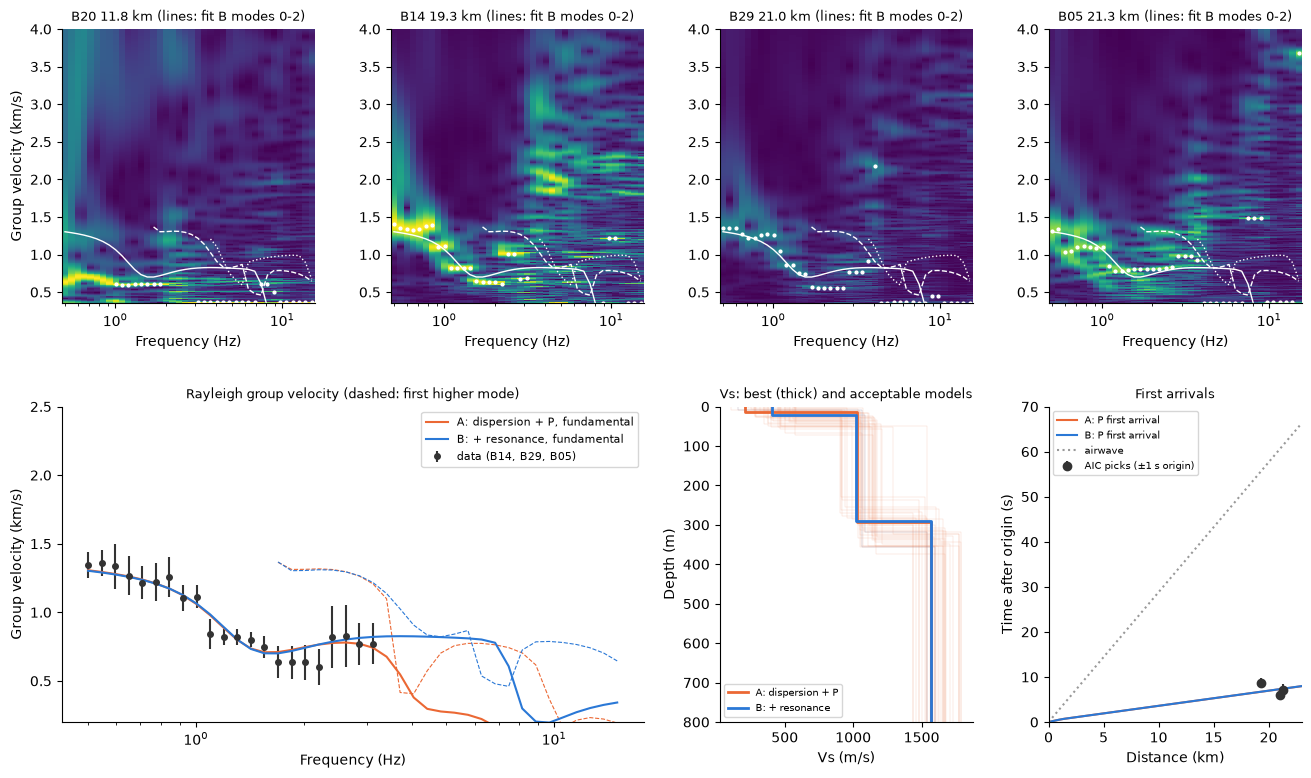

In [6]:
fh = np.geomspace(0.5, 15, 40)
COL = {'A: dispersion + P': '#eb6834', 'B: + resonance': '#2a78d6'}
modes = {k: sw.rayleigh_group(model(b), fh, nmodes=3) for k, b in fits.items()}
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.15], hspace=0.35, wspace=0.3)
for j, sta in enumerate(STAS):
    ax = fig.add_subplot(gs[0, j])
    ax.pcolormesh(F, UG, ftan[sta], shading='auto', cmap='viridis')
    g = disp[(disp.station == sta) & disp.ok]
    ax.plot(g.f_hz, g.U_km_s, 'w.', ms=4)
    for k, ls in zip(range(3), ('-', '--', ':')):
        ax.plot(fh, modes['B: + resonance'][:, k] / 1000, ls, color='#ffffff', lw=1)
    ax.set(xscale='log', ylim=(0.35, 4), xlabel='Frequency (Hz)', title=f"{sta} {air.distance_m[sta] / 1000:.1f} km (lines: fit B modes 0-2)")
    if j == 0:
        ax.set_ylabel('Group velocity (km/s)')
ax = fig.add_subplot(gs[1, 0:2])
ax.errorbar(fobs, Uobs / 1000, yerr=sUobs / 1000, fmt='o', color='#333333', ms=4, label='data (B14, B29, B05)')
for k, mo in modes.items():
    ax.plot(fh, mo[:, 0] / 1000, color=COL[k], lw=1.5, label=f'{k}, fundamental')
    ax.plot(fh, mo[:, 1] / 1000, '--', color=COL[k], lw=0.8)
ax.set(xscale='log', xlabel='Frequency (Hz)', ylabel='Group velocity (km/s)', ylim=(0.2, 2.5),
       title='Rayleigh group velocity (dashed: first higher mode)')
ax.legend(fontsize=8)
ax = fig.add_subplot(gs[1, 2])
zmax = 800
def prof(p):
    h1, vs1, h2, vs2, vs3 = p
    return [0, h1, h1, h1 + h2, h1 + h2, zmax], [vs1, vs1, vs2, vs2, vs3, vs3]
for k, ok in ensembles.items():
    for _, r in ok.sample(min(150, len(ok)), random_state=0).iterrows():
        z, v = prof(r.values[:5])
        ax.plot(v, z, color=COL[k], lw=0.3, alpha=0.3)
    z, v = prof(fits[k])
    ax.plot(v, z, color=COL[k], lw=2, label=k)
ax.set(ylim=(zmax, 0), xlabel='Vs (m/s)', ylabel='Depth (m)', title='Vs: best (thick) and acceptable models')
ax.legend(fontsize=7)
ax = fig.add_subplot(gs[1, 3])
xx = np.linspace(0, 23000, 50)
for k, b in fits.items():
    ax.plot(xx / 1000, sw.first_arrival_times(model(b), xx), color=COL[k], label=f'{k[:1]}: P first arrival')
ax.errorbar(xP / 1000, tP, yerr=sP, fmt='o', color='#333333', label='AIC picks (±1 s origin)')
ax.plot(xx / 1000, xx / air.c_eff_mps.mean(), ':', color='#999999', label='airwave')
ax.set(xlabel='Distance (km)', ylabel='Time after origin (s)', title='First arrivals', xlim=(0, 23), ylim=(0, 70))
ax.legend(fontsize=7)
for a in fig.axes:
    a.title.set_fontsize(9)
fig.savefig(OUT / 'velocity_model.png', dpi=150, bbox_inches='tight')

## What this shows

* **Dispersion.** At B14, B29 and B05 the fundamental-mode Rayleigh group velocity falls from 1.35 km/s at
  0.5 Hz to 0.6–0.8 km/s at 1.5–3 Hz. Above 3 Hz the energy moves to faster branches (1–2 km/s), which the
  model's first higher mode approximately reproduces. B20, on the shortest and most northerly path, shows
  a flat 0.6–0.7 km/s that the model does not fit, so either a different structure or a record too noisy
  to tell.
* **Robust structure (both fits).** Under a thin surface layer, the dispersion needs an intermediate layer
  with Vs ≈ 1.0 km/s (920–1180 m/s), about 270–280 m thick, over a half-space with Vs ≈ 1.57 km/s
  (1.48–1.77; Vp ≈ 3.0 km/s at Vp/Vs = 1.9) from a depth of about 290 m (260–355 m). The half-space P
  speed fits the head-wave first arrivals: 6.7–7.4 s predicted against the 6.0–8.7 s picks.
* **Surface layer.** The 0.5–3 Hz dispersion barely resolves it (fit A: 8–51 m). Adding the ground
  resonance of 4.9 ± 0.5 Hz as the layer's quarter-wavelength S resonance (fit B) gives about 21 m with
  Vs ≈ 410 m/s; only the ratio Vs₁/h₁ ≈ 4 f₀ is really constrained. That agrees with the 15–25 m layer read
  from the compliance in notebook 28.
* **Interpretation (tentative).** Vs ≈ 1 km/s from about 20 m depth is fast for unconsolidated sediments
  and points to lithified carbonate or cemented sediment within a few tens of metres of the surface, with
  a stiffer unit (Vs ≈ 1.6 km/s) near 300 m. Mapping these onto the Hawthorn Group, the Ocala Limestone and
  the Avon Park Formation needs borehole logs at the Cape. Woo et al. (2024, GeoConvention; `references.bib`)
  analysed Rayleigh waves from Artemis I at 2.87 km from LC-39A. They put the Anastasia
  Formation/surficial-aquifer boundary near 9.2 m and the Ocala/Hawthorn boundary near 50 m depth, both
  shallow, as here. Their group velocities (0.09–0.16 km/s at 1–25 s period) are an order of magnitude
  below ours (0.6–1.35 km/s at 0.3–2 s); times from lift-off for an extended, moving launch source make
  apparent velocities lower bounds, whereas the explosion gives an impulsive origin.
* **Limitations.** Three stations at 19–21 km constrain one average 1D path; the P picks scatter by 2.7 s
  between stations at nearly the same distance (B14 8.7 s, B29 6.0 s), more than any 1D model allows, so
  either lateral variation or pick error. The origin uncertainty (±1 s) maps to about ±7% in the
  low-frequency group velocities. Vp in the sediments and all densities are fixed. Next steps: the MSFC
  stations (other paths and distances), horizontal components (Love waves, H/V), and a joint inversion
  with the launch-generated Rayleigh waves recorded across the network.